# Lab 09: How to ask a person before an agent acts

**CPU | API key: `OPENAI_API_KEY` (Part A runs without one)**

Until now the copilot only read. A refund request is a write: the Ops API records it, and someone in finance acts on
it.

## Goal

Make an agent stop before a tool that changes something, show a person the exact call, and continue with their
decision: approve, edit or reject. The moment that teaches it: the rep asks for a refund because two tracks on
Helena's invoice 46 skip, and the copilot proposes to refund all nine tracks, 8.91 dollars (12 of 12 runs on `gpt-4o-mini`). The
reviewer changes the amount to 1.98 before anything runs, and the Ops API files 1.98.

## What you will learn

- How to file a refund request through the Ops API by hand, and which requests its rules refuse or send to a manager.
- How to stop a hand-written agent loop before a write runs, and send a person's decision back as the tool's output.
- How to write a write tool that takes the rep from the run's context, and make it wait with
  `HumanInTheLoopMiddleware`.
- How to read the waiting call from `result.interrupts` and resume the same thread with approve, edit or reject.
- How to check what a write left behind in the API's own table, not only what the reply says.
- How to build an idempotency key so that a retried request files one refund, not two.

## Set up the notebook

Run these two cells first, every time. **Setup** finds the repository folder (on Colab it first copies the repository
and installs the packages). **Config** reads the model names from `models.env` and finds your OpenAI key without
printing it. Lab 00 explains each line.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


⚠️ On Colab, run the setup cell first in a fresh session. If another cell loaded the old `openai` package before the
install, the first model call fails with `ImportError: cannot import name ... from 'openai...'`; use **Runtime →
Restart session** and run from the top.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


`CHAT_MODEL` answers every model call; `EMBED_MODEL` embeds the handbook for `search_policies` from Part C on. The
outputs saved here come from `gpt-4o-mini` on 13 Oct 2026, and your replies will be worded differently.

The picture shows one paused write, from the rep's message to the row in the API's table.

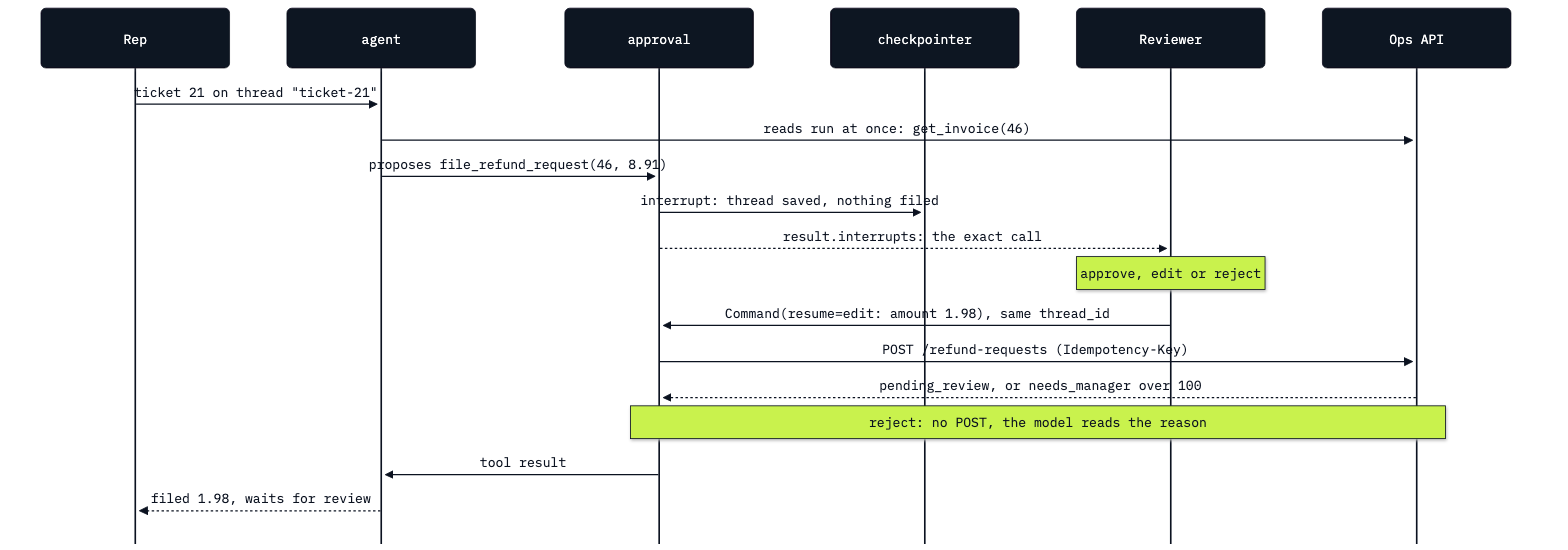

In [3]:
from IPython.display import Image
Image(filename=ROOT / "09_Approval_Before_A_Write" / "resources" / "lab09_approval_flow.png", width=760)

## Start the Ops API

The Ops API is the service you called in Lab 05. Its one write, `POST /refund-requests`, records a refund **request**
in a table of its own; it never changes an invoice or moves money. Start it here, in a background thread.

In [4]:
from shared.ops_api import start_ops_api, OPS_DB

server = start_ops_api()

Ops API started at http://127.0.0.1:8765


---

## Part A: File a refund request by hand

This part sends the write yourself, with no model, so you know what the API accepts before an agent sends anything.

A request has four fields: the invoice, the amount in US dollars, a reason and the rep who files it. The API also
asks for an `Idempotency-Key` header on every write. For now each request gets a new random key (`uuid4`); Part E
shows what the key is for.

Invoice 9003 is a **course fixture**, not Chinook data: a 120.00 box set for customer 16, labelled
`"source": "course fixture"` wherever the API returns it. Predict: is a request for the full 120.00 filed or refused?

In [5]:
import uuid
import httpx
from shared.ops_tools import API

http = httpx.Client(timeout=5.0)          # seconds: a slow API must not hang a turn
body = {"invoice_id": 9003, "amount": 120.00, "reason": "damaged_media", "rep_id": "rep-3"}
response = http.post(f"{API}/refund-requests", json=body, headers={"Idempotency-Key": str(uuid.uuid4())})
print(response.status_code, response.json())

201 {'request_id': 1, 'idempotency_key': 'a00138b7-1005-4628-942b-e80418c7123d', 'invoice_id': 9003, 'amount': 120.0, 'reason': 'damaged_media', 'rep_id': 'rep-3', 'status': 'needs_manager', 'created_at': '2026-10-13T12:33:53+00:00', 'replayed': False}


Status 201: filed, as `needs_manager`. The API sends every request over 100 dollars to the support manager
(`policy_escalations.md`); under 100 it files `pending_review`. That rule lives in the API's code, so no prompt and no
busy reviewer can talk it down. Nobody checked whether the customer should get 120.00 back: called directly, the API
files whatever passes its own rules.

Put the call in a function. A 404 (no such invoice) or a 422 (a rule refused it) comes back as text that starts with
*Not filed*, as in Lab 05, so an agent can read it.

In [6]:
def file_refund(invoice_id, amount, reason, rep_id):
    # POST one refund request; a refusal comes back as text, not as an exception.
    body = {"invoice_id": invoice_id, "amount": amount, "reason": reason, "rep_id": rep_id}
    response = http.post(f"{API}/refund-requests", json=body, headers={"Idempotency-Key": str(uuid.uuid4())})
    if response.status_code in (404, 422):
        return "Not filed: " + response.json()["detail"]
    response.raise_for_status()
    return response.text

print(file_refund(9003, 150.00, "damaged_media", "rep-3"))

Not filed: Amount 150.0 exceeds invoice total 120.0


The API's second rule: an amount above the invoice total is refused with status 422, and nothing is filed.

Now read what the API left behind: its requests live in a SQLite table. You will run `show_rows()` after every write,
because a reply can say anything, and the table is what finance acts on.

In [7]:
import sqlite3

def show_rows():
    # The API's own table, opened read-only: what every write left behind.
    db = sqlite3.connect(f"file:{OPS_DB}?mode=ro", uri=True)
    for row in db.execute("SELECT request_id, invoice_id, amount, status, idempotency_key FROM refund_requests"):
        print(row)
    db.close()

show_rows()

(1, 9003, 120.0, 'needs_manager', 'a00138b7-1005-4628-942b-e80418c7123d')


### Checkpoint A

| You should see | Value |
|---|---|
| The 120.00 request | `201`, `'status': 'needs_manager'`, `'replayed': False` |
| 150.00 on the same invoice | `Not filed: Amount 150.0 exceeds invoice total 120.0` |
| The table | one row: `(1, 9003, 120.0, 'needs_manager', '...')` |

---

## Part B: Stop the loop before a write

This part adds the approval step by hand to Lab 01's loop, so you see that a pause is your code holding back one
function call.

The model gets two tools, described as JSON schemas as in Lab 01: `get_invoice` reads, `file_refund_request` writes.
Look at what the write's schema leaves out: `rep_id`. The model never says who is filing; your code adds it. The
`enum` limits `reason` to the three values the API's records use.

In [8]:
def get_invoice(invoice_id):
    return http.get(f"{API}/invoices/{invoice_id}").text

TOOLS = [
    {"type": "function", "name": "get_invoice", "strict": True,
     "description": "Return one invoice: date, total, customer and its tracks.",
     "parameters": {"type": "object", "additionalProperties": False, "required": ["invoice_id"],
                    "properties": {"invoice_id": {"type": "integer"}}}},
    {"type": "function", "name": "file_refund_request", "strict": True,
     "description": "File a refund request. A person reviews it first.",
     "parameters": {"type": "object", "additionalProperties": False,
                    "required": ["invoice_id", "amount", "reason"],
                    "properties": {"invoice_id": {"type": "integer"},
                                   "amount": {"type": "number", "description": "US dollars, at most the invoice total."},
                                   "reason": {"type": "string", "enum": ["duplicate_charge", "damaged_media", "other"]}}}},
]

The loop is Lab 01's, with one change. A read runs at once. A call to a tool in `WRITES` is not run: the loop returns
it, with the conversation so far kept in `history`.

In [9]:
import json
from openai import OpenAI

client = OpenAI()
SYSTEM = ("You help Chinook support reps. Before you file a refund, read each invoice with get_invoice. "
          "A filed refund request waits for a person to review it. Never say that money has been sent.")
WRITES = {"file_refund_request"}

def run(history):
    # Lab 01's loop. The one change: a write is returned, not run.
    while True:
        response = client.responses.create(model=settings["CHAT_MODEL"], instructions=SYSTEM,
                                           input=history, tools=TOOLS)
        history += response.output
        calls = [item for item in response.output if item.type == "function_call"]
        if not calls:
            return response.output_text, []
        for call in calls:
            if call.name not in WRITES:
                output = get_invoice(**json.loads(call.arguments))
                history.append({"type": "function_call_output", "call_id": call.call_id, "output": output})
        writes = [call for call in calls if call.name in WRITES]
        if writes:
            return None, writes          # the gate: stop before a write runs

Ticket 22 comes from the box set's owner: one of its four discs arrived cracked. Predict: which calls does the model
make before the loop stops?

In [10]:
TICKET_22 = ("Ticket 22: customer 16's box set on invoice 9003 arrived with one of its four discs cracked. "
             "Please file a refund.")
history = [{"role": "user", "content": TICKET_22}]
reply, pending = run(history)

print("calls made:", [item.name for item in history if getattr(item, "type", "") == "function_call"])
print("reply:", reply)
for call in pending:
    print("waiting:", call.name, call.arguments)
show_rows()

calls made: ['get_invoice', 'file_refund_request']
reply: None
waiting: file_refund_request {"invoice_id":9003,"amount":120,"reason":"damaged_media"}
(1, 9003, 120.0, 'needs_manager', 'a00138b7-1005-4628-942b-e80418c7123d')


The model read invoice 9003 and asked to refund all of it: `{"invoice_id":9003,"amount":120,"reason":"damaged_media"}`. The call waits in `pending`, exactly as the model wrote it, and the table still holds only Part A's row:
nothing was sent.

A person can now decide. `policy_damaged_media.md` says a cracked disc is replaced at no charge, not refunded, so the
answer is no. A decision goes back as a `function_call_output` for the waiting call. To approve, you would run
`file_refund(**arguments, rep_id="rep-3")` and send its result; to reject, send the reason, written for the model:
what happened, and what to do next.

In [11]:
if not pending:              # the model answered without asking to file: nothing waits
    print("⚠️ No call waits. Run the cell above again to start a new conversation.")
else:
    call = pending[0]
    history.append({"type": "function_call_output", "call_id": call.call_id,
                    "output": "Not filed: a reviewer rejected it. Damaged discs are replaced at no charge, "
                              "not refunded (policy_damaged_media.md). Tell the rep to send a replacement disc."})
    reply, pending = run(history)
    print(reply)
show_rows()

The refund request for invoice 9003 was not filed because damaged discs are replaced at no charge per our policy. Please inform the support rep to send a replacement disc for the cracked disc in the box set.
(1, 9003, 120.0, 'needs_manager', 'a00138b7-1005-4628-942b-e80418c7123d')


The reply tells the rep the request was rejected and to send a replacement disc. The table still has one row.

The whole pause was two variables in this kernel, `history` and `pending`. A restart loses both, and nothing records
which call is waiting or who decided. The next part saves the thread with a checkpointer instead.

### Checkpoint B

| You should see | Our run |
|---|---|
| The waiting call | `file_refund_request` for invoice 9003 after one `get_invoice` (ours: `{"invoice_id":9003,"amount":120,"reason":"damaged_media"}`); no new row |
| After the rejection | a reply about a replacement disc; still one row |

---

## Part C: Pause with `HumanInTheLoopMiddleware` and approve

This part rebuilds the gate with LangChain: a write tool, a middleware that stops before it, and a saved thread you
resume with a decision.

### Write the refund tool

Write it with `@tool`, as in Lab 05. Three choices matter for a write:

- `reason` is a `Literal`, so the schema lists the three values, as the `enum` did in Part B.
- The rep comes from `ToolRuntime[RepContext]`, the run's context (Lab 05). The model never sees it, so nothing typed
  in the chat can file a request in another rep's name.
- The key comes from `idempotency_key`, a random key for now. Part E redefines that function; the tool looks it up
  each time it runs.

In [12]:
from typing import Literal
from langchain.tools import ToolRuntime, tool
from shared.ops_tools import RepContext

def idempotency_key(runtime, invoice_id, amount):
    return str(uuid.uuid4())             # a new key for every request; Part E changes this

@tool(parse_docstring=True)
def file_refund_request(invoice_id: int, amount: float,
                        reason: Literal["duplicate_charge", "damaged_media", "other"],
                        runtime: ToolRuntime[RepContext]) -> str:
    """File a refund request. A person reviews it first.

    Args:
        invoice_id: The invoice to refund, digits only.
        amount: US dollars, at most the invoice total.
        reason: Why the refund is due.
    """
    body = {"invoice_id": invoice_id, "amount": amount, "reason": reason, "rep_id": runtime.context.rep_id}
    key = idempotency_key(runtime, invoice_id, amount)
    response = http.post(f"{API}/refund-requests", json=body, headers={"Idempotency-Key": key})
    if response.status_code in (404, 422):
        return "Not filed: " + response.json()["detail"]
    response.raise_for_status()
    return response.text

In [13]:
print(json.dumps(file_refund_request.tool_call_schema.model_json_schema()["properties"], indent=1))

{
 "invoice_id": {
  "description": "The invoice to refund, digits only.",
  "title": "Invoice Id",
  "type": "integer"
 },
 "amount": {
  "description": "US dollars, at most the invoice total.",
  "title": "Amount",
  "type": "number"
 },
 "reason": {
  "description": "Why the refund is due.",
  "enum": [
   "duplicate_charge",
   "damaged_media",
   "other"
  ],
  "title": "Reason",
  "type": "string"
 }
}


The model sees `invoice_id`, `amount` and `reason` with its three values. `runtime` is not in the schema.

### Make the write wait

`HumanInTheLoopMiddleware` (**HITL**, human in the loop) runs after each model reply and before any tool. When the
reply asks for a tool named in `interrupt_on`, it stops the run with an **interrupt**: the thread is saved, nothing
runs, and the waiting call goes to your code. Tools not named run straight away. Each entry lists the decisions a
reviewer may send. A misspelt name raises no error and leaves that tool without a pause, so check the names. An entry
can also take a `when` function that pauses only some calls (langchain 1.3.3 and later); here every refund waits.

A pause must be saved to be resumed, so the agent needs a checkpointer and each run a `thread_id` (Lab 03). The reads
come from `shared/`: `get_invoice` (Lab 05) and `search_policies` (Lab 08).

In [14]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from shared import ops_tools
from shared.copilot import search_policies
from shared.settings import chat_model

PROMPT = ("You help Chinook support reps.\n"
          "Before you file a refund, read each invoice with get_invoice and check the rule with search_policies.\n"
          "A filed refund request waits for a person to review it. Never say that money has been sent.")
TOOLS = [search_policies, ops_tools.get_invoice, file_refund_request]
approval = HumanInTheLoopMiddleware(interrupt_on={
    "file_refund_request": {"allowed_decisions": ["approve", "edit", "reject"]}})

agent = create_agent(chat_model(settings), tools=TOOLS, system_prompt=PROMPT, middleware=[approval],
                     checkpointer=InMemorySaver(), context_schema=RepContext)
REP = RepContext(rep_id="rep-3", rep_name="Jane Peacock")

`chat_model()` reads `CHAT_MODEL` from `models.env` and uses the Responses API. Ticket 23 is one a reviewer should
approve: both tracks on Helena's invoice 175 skip, and the invoice holds just those two tracks. `version="v2"` makes
`invoke` return an object with the state in `.value` and any pause in `.interrupts`. Predict: how far does the run get?

In [15]:
TICKET_23 = "Ticket 23: Helena Holý (customer 6) says both tracks on invoice 175 skip on every play. Please file a refund."
cfg = {"configurable": {"thread_id": "ticket-23"}}
paused = agent.invoke({"messages": [("user", TICKET_23)]}, cfg, context=REP, version="v2")

for message in paused.value["messages"]:
    if message.type == "ai":
        print("ai   ", [(c["name"], c["args"]) for c in message.tool_calls] or message.text)
    else:
        print(f"{message.type:5}", message.name or message.text)

human Ticket 23: Helena Holý (customer 6) says both tracks on invoice 175 skip on every play. Please file a refund.
ai    [('get_invoice', {'invoice_id': 175}), ('search_policies', {'query': 'refund policy for damaged media'})]
tool  get_invoice
tool  search_policies
ai    [('file_refund_request', {'invoice_id': 175, 'amount': 1.98, 'reason': 'damaged_media'})]


The model read invoice 175 and searched the handbook in one step (two tool calls in one message), then asked to file 1.98, the invoice's total, with the reason `damaged_media`. The last AI message asks for `file_refund_request`, and no tool message follows it: the run stopped between
the model's reply and the tool. Here is what your code receives, where the run waits, and what the table holds.

A run pauses only if the model asks for the write. If it answers without asking, `paused.interrupts` is empty and
`interrupts[0]` would fail with an `IndexError` that says nothing useful. `waiting_call` reads the first waiting call,
and stops with a plain message when there is none; every later cell reads the pause through it.

In [16]:
def waiting_call(paused):
    # The first call a paused run waits on; a plain error when the run ended without a pause.
    if not paused.interrupts:
        raise RuntimeError("No pause: the run ended without asking to file. Its reply: "
                           + paused.value["messages"][-1].text[:200] + " Run the cell that asked again.")
    return paused.interrupts[0].value["action_requests"][0]

waiting_call(paused)
request = paused.interrupts[0].value
print(json.dumps(request, indent=1))
print("next step:", agent.get_state(cfg).next)
show_rows()

{
 "action_requests": [
  {
   "name": "file_refund_request",
   "args": {
    "invoice_id": 175,
    "amount": 1.98,
    "reason": "damaged_media"
   },
   "description": "Tool execution requires approval\n\nTool: file_refund_request\nArgs: {'invoice_id': 175, 'amount': 1.98, 'reason': 'damaged_media'}"
  }
 ],
 "review_configs": [
  {
   "action_name": "file_refund_request",
   "allowed_decisions": [
    "approve",
    "edit",
    "reject"
   ]
  }
 ]
}
next step: ('HumanInTheLoopMiddleware.after_model',)
(1, 9003, 120.0, 'needs_manager', 'a00138b7-1005-4628-942b-e80418c7123d')


`action_requests` holds the exact call and a default description; `review_configs` lists the decisions allowed. The
thread waits before the middleware's step, as long as needed, and the table has no new row.

Two tracks at 0.99, both skip: 1.98 is right. To approve, invoke the agent with a `Command` whose `resume` value holds
one decision per waiting call, on the **same** `thread_id`, so the saved run continues instead of starting anew.

In [17]:
from langgraph.types import Command

done = agent.invoke(Command(resume={"decisions": [{"type": "approve"}]}), cfg, context=REP, version="v2")
print("tool: ", done.value["messages"][-2].text)
print("reply:", done.value["messages"][-1].text)
show_rows()

tool:  {"request_id":2,"idempotency_key":"c52a8480-6887-4fcb-b917-d7c28d083f37","invoice_id":175,"amount":1.98,"reason":"damaged_media","rep_id":"rep-3","status":"pending_review","created_at":"2026-10-13T12:34:01+00:00","replayed":false}
reply: I have filed a refund request for invoice 175 due to the damaged media reported by Helena Holý. The request is currently pending review. If you need any further assistance, feel free to ask!
(1, 9003, 120.0, 'needs_manager', 'a00138b7-1005-4628-942b-e80418c7123d')
(2, 175, 1.98, 'pending_review', 'c52a8480-6887-4fcb-b917-d7c28d083f37')


The tool ran with the arguments the reviewer saw: request 2, invoice 175, 1.98, `pending_review`, with `rep-3` from the context. The reply says the request is pending review.

### Checkpoint C

| You should see | Our run |
|---|---|
| Before the pause | reads only (ours: `get_invoice` and `search_policies` in one step) |
| The interrupt | `file_refund_request` with invoice 175 and 1.98; approve, edit, reject allowed; no new row |
| After approval | a new row: invoice 175, 1.98, `pending_review` |

---

## Part D: Edit or reject the waiting call

This part changes one call before it runs, refuses another, and shows what the model reads after each.

### Change the amount

Ticket 21 reads like ticket 23, but invoice 46 holds nine tracks, and only two of them skip. Predict the amount the
copilot proposes.

In [18]:
TICKET_21 = "Ticket 21: Helena Holý (customer 6) says two tracks on invoice 46 skip on every play. Please file a refund."
cfg = {"configurable": {"thread_id": "ticket-21"}}
paused = agent.invoke({"messages": [("user", TICKET_21)]}, cfg, context=REP, version="v2")
proposed = waiting_call(paused)
print(proposed["name"], proposed["args"])

file_refund_request {'invoice_id': 46, 'amount': 8.91, 'reason': 'damaged_media'}


The copilot proposes the whole invoice, 8.91 dollars, for two tracks (12 of 12 runs on `gpt-4o-mini`). It read the invoice and
searched the handbook, whose refunds policy allows a partial refund, and still asked for all nine tracks. Without
the pause, 8.91 would now be in the table. The reviewer checks the invoice:

In [19]:
invoice = http.get(f"{API}/invoices/46").json()
print(len(invoice["lines"]), "tracks, total", invoice["total"], "| prices:", {line["unit_price"] for line in invoice["lines"]})

9 tracks, total 8.91 | prices: {0.99}


Nine tracks at 0.99: the two that skip are 1.98. An **edit** decision carries the whole call to run instead, its name
and arguments. Keep what the model got right and change only the amount.

In [20]:
edit = {"type": "edit", "edited_action": {"name": proposed["name"], "args": {**proposed["args"], "amount": 1.98}}}
done = agent.invoke(Command(resume={"decisions": [edit]}), cfg, context=REP, version="v2")
print(done.value["messages"][-2].text)
show_rows()

Note: a human reviewer replaced this tool call before it ran. The call recorded in your message is the one you produced, not the one that executed. This was intentional and authorized. Do not re-issue your original call. Executed instead: file_refund_request with arguments {"invoice_id": 46, "amount": 1.98, "reason": "damaged_media"}.

Tool response:
{"request_id":3,"idempotency_key":"35ff866f-a50d-405e-a70c-15ceff1eeb5b","invoice_id":46,"amount":1.98,"reason":"damaged_media","rep_id":"rep-3","status":"pending_review","created_at":"2026-10-13T12:34:05+00:00","replayed":false}
(1, 9003, 120.0, 'needs_manager', 'a00138b7-1005-4628-942b-e80418c7123d')
(2, 175, 1.98, 'pending_review', 'c52a8480-6887-4fcb-b917-d7c28d083f37')
(3, 46, 1.98, 'pending_review', '35ff866f-a50d-405e-a70c-15ceff1eeb5b')


The tool ran with 1.98, and the newest row is invoice 46 at 1.98. The tool message starts with a note from the
middleware: a reviewer replaced the call on purpose, so do not send the original again. Without it, the model would
see a result for 1.98 beside its own request for 8.91 and might try again. The thread keeps both:

In [21]:
asked = [m for m in done.value["messages"] if m.type == "ai" and m.tool_calls][-1]
print("the model asked for:", asked.tool_calls[0]["args"])
print("the reply:", done.value["messages"][-1].text)

the model asked for: {'invoice_id': 46, 'amount': 8.91, 'reason': 'damaged_media'}
the reply: I have filed a refund request for Helena Holý regarding the two tracks that skip on her invoice. The refund amount is $1.98, and the request is currently pending review.


The model's own message still asks for 8.91; the tool ran with 1.98, and the reply states $1.98, pending review. After an edit, check that the reply states what was filed. The LangChain documentation advises small
edits, such as an amount: a large change can make the model re-plan and call tools again.

### Reject

Now ticket 22, the box set from Part B, through the middleware. A **reject** decision carries a `message`, which the
model reads in place of a tool result.

In [22]:
cfg = {"configurable": {"thread_id": "ticket-22"}}
paused = agent.invoke({"messages": [("user", TICKET_22)]}, cfg, context=REP, version="v2")
print("proposed:", waiting_call(paused)["args"])

reject = {"type": "reject", "message": "Do not file: damaged discs are replaced at no charge, not refunded "
                                       "(policy_damaged_media.md). Tell the rep to send a replacement disc."}
done = agent.invoke(Command(resume={"decisions": [reject]}), cfg, context=REP, version="v2")
print("tool: ", done.value["messages"][-2].status, "|", done.value["messages"][-2].text)
print("reply:", done.value["messages"][-1].text)
show_rows()

proposed: {'invoice_id': 9003, 'amount': 120, 'reason': 'damaged_media'}


tool:  error | User rejected the tool call for `file_refund_request` with reason: Do not file: damaged discs are replaced at no charge, not refunded (policy_damaged_media.md). Tell the rep to send a replacement disc.
reply: Since the box set arrived with a cracked disc, we can't file a refund. According to our policy, we replace damaged discs at no charge. Please reach out to the customer and arrange for a replacement disc.
(1, 9003, 120.0, 'needs_manager', 'a00138b7-1005-4628-942b-e80418c7123d')
(2, 175, 1.98, 'pending_review', 'c52a8480-6887-4fcb-b917-d7c28d083f37')
(3, 46, 1.98, 'pending_review', '35ff866f-a50d-405e-a70c-15ceff1eeb5b')


The model proposed the full 120.00 again. After the rejection it told the rep to send a replacement disc, and no row was added. The middleware wrote the tool message you wrote by hand in Part B, with status `error`. Write the reason
for the model: what happened and what to do next (Challenge 3 tries a rejection without one).

The fourth decision, `respond`, returns your text as a successful tool result. It is meant for a tool whose answer
comes from a person, such as an "ask the rep" tool; on a write the model would read it as done.

### Checkpoint D

| You should see | Our run |
|---|---|
| Ticket 21's proposal | invoice 46 for the full 8.91 (ours: `{'invoice_id': 46, 'amount': 8.91, 'reason': 'damaged_media'}`) |
| After the edit | *Note: a human reviewer replaced this tool call before it ran*; a new row for invoice 46 at 1.98 |
| Ticket 22 rejected | status `error` with your reason; a reply about a replacement disc; no new row |

If your copilot proposes 1.98 for ticket 21, it got the amount right this time. Run the edit anyway: it sends 1.98
back, and you still see the middleware's note and the row.

---

## Part E: Make a retry file one refund

This part makes the write safe to retry: one approved request files one refund, however often it is sent.

The worst failure for a write is a reply lost on the way back: the API filed the request, but the copilot saw a
timeout. Retrying after a timeout is normal, and `ToolRetryMiddleware` (Lab 05) does it for you.

To see it, replace the HTTP client with one that loses the first reply to a write: the API files the request, then
the client raises `ReadTimeout` as if no answer came. The tool uses the new `http` from its next call.

In [23]:
lost = []

def lose_first_reply(response):
    # The API has answered; act as if the answer never arrived, once.
    if response.request.method == "POST" and not lost:
        lost.append(response.request.headers["Idempotency-Key"])
        raise httpx.ReadTimeout("no answer from the Ops API", request=response.request)

http = httpx.Client(timeout=5.0, event_hooks={"response": [lose_first_reply]})

You have run a ticket to the pause and approved it twice, so put those steps in one function, with the retry
middleware added after the approval. The case is ticket 14, the course fixture's duplicate charge: invoices 9001 and
9002 both charged 9.99 for one album on one day, and the refunds policy says to refund the later one.

In [24]:
from langchain.agents.middleware import ToolRetryMiddleware

TICKET_14 = ("Ticket 14: the customer was charged twice for The Essential Miles Davis on 2013-11-02. "
             "Invoices 9001 and 9002. Please sort it out.")
retry = ToolRetryMiddleware(tools=["file_refund_request"], retry_on=(httpx.ReadTimeout,), max_retries=1,
                            initial_delay=0)

def approve_once(thread_id):
    # A new copilot, ticket 14 on its own thread, one approval.
    agent = create_agent(chat_model(settings), tools=TOOLS, system_prompt=PROMPT, middleware=[approval, retry],
                         checkpointer=InMemorySaver(), context_schema=RepContext)
    cfg = {"configurable": {"thread_id": thread_id}}
    paused = agent.invoke({"messages": [("user", TICKET_14)]}, cfg, context=REP, version="v2")
    print("approved:", waiting_call(paused)["args"])
    done = agent.invoke(Command(resume={"decisions": [{"type": "approve"}]}), cfg, context=REP, version="v2")
    print("tool:    ", done.value["messages"][-2].text)
    print("reply:   ", done.value["messages"][-1].text)

Predict: how many new rows does one approval leave?

In [25]:
approve_once("ticket-14")
print("reply lost for key:", lost)
show_rows()

approved: {'invoice_id': 9002, 'amount': 9.99, 'reason': 'duplicate_charge'}


tool:     {"request_id":5,"idempotency_key":"87a430c3-f636-403b-a635-8bbc5c7c89cd","invoice_id":9002,"amount":9.99,"reason":"duplicate_charge","rep_id":"rep-3","status":"pending_review","created_at":"2026-10-13T12:34:12+00:00","replayed":false}
reply:    I've filed a refund request for the duplicate charge on the second invoice (9002) for "The Essential Miles Davis." The request for $9.99 is now pending review. If you need any further assistance, feel free to ask!
reply lost for key: ['5291bd2e-5962-4273-8f2b-0f081832c547']
(1, 9003, 120.0, 'needs_manager', 'a00138b7-1005-4628-942b-e80418c7123d')
(2, 175, 1.98, 'pending_review', 'c52a8480-6887-4fcb-b917-d7c28d083f37')
(3, 46, 1.98, 'pending_review', '35ff866f-a50d-405e-a70c-15ceff1eeb5b')
(4, 9002, 9.99, 'pending_review', '5291bd2e-5962-4273-8f2b-0f081832c547')
(5, 9002, 9.99, 'pending_review', '87a430c3-f636-403b-a635-8bbc5c7c89cd')


One approval, two new rows for invoice 9002 at 9.99: requests 4 and 5. The first attempt was filed and its reply lost; the retry carried a new random key, so the API saw a new
request. The reply describes one request. Only the table shows the second.

An **idempotency key** names an operation you mean to perform once. The API files the first request with a key and
answers any later request with the same key by returning that first request, marked `"replayed": true`. So the key
must be the same on every attempt at the same refund. Build it from what makes two requests the same refund: the
conversation (`thread_id`, from the run's config), the invoice and the amount.

In [26]:
def idempotency_key(runtime, invoice_id, amount):
    # The same refund in the same conversation gets the same key, so a retry files nothing new.
    thread_id = runtime.config["configurable"]["thread_id"]
    return f"{thread_id}:{invoice_id}:{amount:.2f}"

Run the same test on a new thread, with the first reply lost again:

In [27]:
lost.clear()
approve_once("ticket-14-again")
print("reply lost for key:", lost)
show_rows()

approved: {'invoice_id': 9002, 'amount': 9.99, 'reason': 'duplicate_charge'}


tool:     {"request_id":6,"idempotency_key":"ticket-14-again:9002:9.99","invoice_id":9002,"amount":9.99,"reason":"duplicate_charge","rep_id":"rep-3","status":"pending_review","created_at":"2026-10-13T12:34:16+00:00","replayed":true}
reply:    I filed a refund request for the duplicate charge on the second invoice (9002) for "The Essential Miles Davis." The request is pending review. 

If you have any further questions or need assistance with anything else, feel free to ask!
reply lost for key: ['ticket-14-again:9002:9.99']
(1, 9003, 120.0, 'needs_manager', 'a00138b7-1005-4628-942b-e80418c7123d')
(2, 175, 1.98, 'pending_review', 'c52a8480-6887-4fcb-b917-d7c28d083f37')
(3, 46, 1.98, 'pending_review', '35ff866f-a50d-405e-a70c-15ceff1eeb5b')
(4, 9002, 9.99, 'pending_review', '5291bd2e-5962-4273-8f2b-0f081832c547')
(5, 9002, 9.99, 'pending_review', '87a430c3-f636-403b-a635-8bbc5c7c89cd')
(6, 9002, 9.99, 'pending_review', 'ticket-14-again:9002:9.99')


One new row, request 6, key `ticket-14-again:9002:9.99`. The retry sent the same key, and the API returned the same request with `"replayed":true`. The rep's reply reads as it did in the first run; only the table shows the difference.

The table now holds three requests for ticket 14's charge, because this run was a separate conversation with its own
key. The key stops a retry, not a second conversation (Challenge 1). In production the service also keeps the business
rule itself, for example that refunds on one invoice never add up to more than its total.

### Checkpoint E

| You should see | Our run |
|---|---|
| Random keys, one lost reply | two new rows for invoice 9002 at 9.99 (ours: requests 4 and 5) |
| Key from the request | one new row, key `ticket-14-again:9002:9.99`; the tool's result has `"replayed":true` |

---

## Going further

### Give the reviewer a review screen

A reviewer deciding on a refund wants more than the arguments: the invoice and the policies the copilot read. In
`interrupt_on`, `description` can be a function of the waiting call, the agent's state and the run; its text replaces
the default. This one reads the invoice and the files `search_policies` returned (its artifact, Lab 08).

In [28]:
def review_screen(tool_call, state, runtime):
    # What the reviewer reads before deciding: the call, the invoice, the policies the copilot read.
    args = tool_call["args"]
    invoice = http.get(f"{API}/invoices/{args['invoice_id']}").json()
    read = sorted({hit["source"] for m in state["messages"]
                   if m.type == "tool" and m.name == "search_policies" for hit in m.artifact or []})
    return "\n".join([f"Refund {args['amount']:.2f} on invoice {args['invoice_id']} ({args['reason']})",
                      f"Invoice: {invoice['date']}, {len(invoice['lines'])} tracks, total {invoice['total']}",
                      f"Policies the copilot read: {', '.join(read) or 'none'}"])

Run ticket 21 to the pause with it:

In [29]:
screened = HumanInTheLoopMiddleware(interrupt_on={"file_refund_request": {
    "allowed_decisions": ["approve", "edit", "reject"], "description": review_screen}})
agent = create_agent(chat_model(settings), tools=TOOLS, system_prompt=PROMPT, middleware=[screened],
                     checkpointer=InMemorySaver(), context_schema=RepContext)
cfg = {"configurable": {"thread_id": "ticket-21-screen"}}
paused = agent.invoke({"messages": [("user", TICKET_21)]}, cfg, context=REP, version="v2")
print(waiting_call(paused)["description"])

Refund 8.91 on invoice 46 (damaged_media)
Invoice: 2009-07-11, 9 tracks, total 8.91
Policies the copilot read: policy_damaged_media.md, policy_exchanges.md, policy_refunds.md, policy_returns.md


The reviewer now sees nine tracks beside the 8.91, and the four files the copilot read, among them `policy_refunds.md` with its partial-refund rule. Keep a function like this read-only: when the run resumes, the middleware's step starts again, so the
function runs a second time.

### Keep a pause across a restart

A reviewer may answer tomorrow, after a restart, and `InMemorySaver` lives in this kernel's memory.
`SqliteSaver` (Lab 03) keeps the pause in a file; for production the LangChain documentation recommends a database
such as Postgres. Pause ticket 22 into a file, then open it from a new agent, as a restarted app would.

In [30]:
import tempfile
from langgraph.checkpoint.sqlite import SqliteSaver

APPROVALS = Path(tempfile.gettempdir()) / "lab09_approvals.sqlite"
APPROVALS.unlink(missing_ok=True)

def copilot_on(path):
    saver = SqliteSaver(sqlite3.connect(path, check_same_thread=False))
    return create_agent(chat_model(settings), tools=TOOLS, system_prompt=PROMPT, middleware=[approval],
                        checkpointer=saver, context_schema=RepContext)

evening = {"configurable": {"thread_id": "ticket-22-evening"}}
waiting_call(copilot_on(APPROVALS).invoke({"messages": [("user", TICKET_22)]}, evening, context=REP, version="v2"))

morning = copilot_on(APPROVALS)
print("still waiting:", morning.get_state(evening).interrupts[0].value["action_requests"][0]["args"])

still waiting: {'invoice_id': 9003, 'amount': 120, 'reason': 'damaged_media'}


The pause survived. Now an easy mistake: the decision arrives with a mistyped thread id. Predict: an error?

In [31]:
typo = {"configurable": {"thread_id": "ticket-22-evenin"}}
wrong = morning.invoke(Command(resume={"decisions": [{"type": "approve"}]}), typo, context=REP, version="v2")
print("reply:", wrong.value["messages"][-1].text)
print("ticket-22-evening still waiting:", bool(morning.get_state(evening).interrupts))

reply: Got it! If you need assistance with filing a refund or checking an invoice, just provide the invoice number and the reason for the refund. I'll also check the relevant rules to ensure everything is in order. Let me know how you'd like to proceed!
ticket-22-evening still waiting: True


The model answered an empty conversation (*Got it! If you need assistance with filing a refund or checking an invoice, just provide the invoice number ...*), and ticket 22's thread is still waiting. No error: a thread with no saved state has nothing to resume, so the agent started a new run on an empty
conversation. The reviewer would believe the decision was sent. Check `agent.get_state(cfg).interrupts` first, and
refuse when it is empty.

Stop the API when you have finished:

In [32]:
if server is not None:
    server.should_exit = True

## What you can do now

- File a refund request by hand, and say which ones the API refuses (422) or sends to the manager (`needs_manager`).
- Stop a hand-written Responses loop before a write, and send a decision back as the tool's output.
- Write a write tool that takes the rep from `ToolRuntime` context, and make it wait with `HumanInTheLoopMiddleware`.
- Resume a waiting thread with approve, edit or reject, knowing what the model reads after each.
- Read the API's own table after every write, and catch two rows where the reply describes one.
- Build an idempotency key so that a retried request files one refund.

## Challenge

A worked solution is in `solved/` for the instructor. Task 1 is the challenge; tasks 2 and 3 are optional. For each
task, keep the printed results and your answer to Explain. The next cell starts the Ops API again, with an empty
table: the last cell of Going further stopped it.

1. **A key for the refund, not the conversation.** Part E's key stops a retry inside one conversation. What happens
   when two conversations ask for the same refund?

   **Start from** the cells under **Task 1** below: `approve_on(thread_id)` runs ticket 14 on its own thread and approves the
   proposal once. The cell approves it on two new threads with Part E's key and prints the table.

   - Predict how many new rows the two approvals leave.
   - Complete `refund_key` in the cells under **Task 1** below: a key from the invoice and the amount only, such as
     `refund:9002:9.99`. The cell then approves ticket 14 on two more threads with it.

   **Check:** with Part E's key, two new rows for invoice 9002 at 9.99, keys `monday:9002:9.99` and
   `tuesday:9002:9.99`. With your key, one new row; the second conversation's tool result is that request again, with
   `"replayed":true`.

   **Explain:** name a request your key would wrongly swallow. If a key cannot stop a second refund for one charge,
   what should?

2. **Optional: two refunds in one step.** A model can ask for two writes in one message. **Start from** the cells under
   **Task 2** below: a scripted model (no API call) proposes refunds on 9001 and 9002 at once, and the run pauses. Resume with
   one decision, then with two (reject 9001 with a reason, approve 9002).

   **Check:** one interrupt with two action requests, and what each resume does. Then read the Troubleshooting table.

   **Explain:** why does the second resume fail the way it does, and what clears it?

3. **Optional: reject without a reason.** **Start from** the cells under **Task 3** below: it rejects ticket 22 on three threads
   with the decision you write in `NO_REASON`, a rejection with no `message`.

   **Check:** the tool message the model reads, and three replies.

   **Explain:** compare the replies with Part D's rejection. What does the model do when it is not told why?

In [ ]:
server = start_ops_api()      # Going further stopped the Ops API; this starts it with an empty table

**Task 1.** A fresh copilot, `approve_on`, and two conversations with Part E's key:

In [ ]:
http = httpx.Client(timeout=5.0)          # a plain client again: Part E's loses a reply
challenge_agent = create_agent(chat_model(settings), tools=TOOLS, system_prompt=PROMPT, middleware=[approval],
                               checkpointer=InMemorySaver(), context_schema=RepContext)


def approve_on(thread_id):
    # Ticket 14 on its own thread, approved once; prints what the tool returned.
    cfg = {"configurable": {"thread_id": thread_id}}
    paused = challenge_agent.invoke({"messages": [("user", TICKET_14)]}, cfg, context=REP, version="v2")
    print(thread_id, "proposed:", waiting_call(paused)["args"])
    done = challenge_agent.invoke(Command(resume={"decisions": [{"type": "approve"}]}), cfg, context=REP, version="v2")
    print("   tool:", done.value["messages"][-2].text)


for thread_id in ("monday", "tuesday"):
    approve_on(thread_id)
show_rows()

`refund_key` to complete. The tool looks `idempotency_key` up each time it runs, so the cell swaps yours in:

In [ ]:
def refund_key(runtime, invoice_id, amount):
    # TODO: return a key made from the invoice and the amount only, for example "refund:9002:9.99"
    raise NotImplementedError("Complete refund_key.")


try:
    print("your key:", refund_key(None, 9002, 9.99))
    idempotency_key = refund_key
    for thread_id in ("wednesday", "thursday"):
        approve_on(thread_id)
    show_rows()
except NotImplementedError as error:
    print("⚠️", error)

**Task 2 (optional).** SCRIPTED MODEL · NO API CALL. Two proposals in one message, and the pause:

In [ ]:
from langchain_core.messages import AIMessage
from shared.scripted import scripted

BOTH = AIMessage(content="", tool_calls=[
    {"name": "file_refund_request", "args": {"invoice_id": 9001, "amount": 9.99, "reason": "duplicate_charge"},
     "id": "call_9001"},
    {"name": "file_refund_request", "args": {"invoice_id": 9002, "amount": 9.99, "reason": "duplicate_charge"},
     "id": "call_9002"}])
two = create_agent(scripted(BOTH, AIMessage(content="(scripted) Done.")), tools=TOOLS, middleware=[approval],
                   checkpointer=InMemorySaver(), context_schema=RepContext)
two_cfg = {"configurable": {"thread_id": "two-at-once"}}
paused = two.invoke({"messages": [("user", TICKET_14)]}, two_cfg, context=REP, version="v2")
for action in paused.interrupts[0].value["action_requests"]:
    print(action["name"], action["args"])

ATTEMPTS = [
    # TODO: one list of decisions per resume: first [{"type": "approve"}], then a reject for 9001 with a message
    #       and an approve for 9002
]
for decisions in ATTEMPTS:
    try:
        two.invoke(Command(resume={"decisions": decisions}), two_cfg, context=REP, version="v2")
        print(len(decisions), "decision(s): resumed")
    except ValueError as error:
        print(len(decisions), "decision(s): ValueError:", error)
if not ATTEMPTS:
    print("⚠️ Write your resumes in ATTEMPTS.")

**Task 3 (optional).** Ticket 22 rejected three times with your `NO_REASON`:

In [ ]:
NO_REASON = None          # TODO: a reject decision with no "message"

if NO_REASON is None:
    print("⚠️ Write your decision in NO_REASON.")
else:
    for n in (1, 2, 3):
        cfg = {"configurable": {"thread_id": f"no-reason-{n}"}}
        paused = challenge_agent.invoke({"messages": [("user", TICKET_22)]}, cfg, context=REP, version="v2")
        print(n, "proposed:", waiting_call(paused)["args"])
        done = challenge_agent.invoke(Command(resume={"decisions": [NO_REASON]}), cfg, context=REP, version="v2")
        if n == 1:
            print("tool message:", done.value["messages"][-2].status, "|", done.value["messages"][-2].text)
        print("   reply:", done.value["messages"][-1].text)
    show_rows()

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `RuntimeError: No pause: the run ended without asking to file` | the model answered without proposing a refund (ours proposed one in every run) | read the reply it printed, then run the cell that asked again |
| The run never pauses and the refund is filed | the tool's name is missing or misspelt in `interrupt_on` (no error is raised) | compare the names in `interrupt_on` with every write tool's `.name` |
| `AttributeError: 'dict' object has no attribute 'interrupts'` | `invoke` was called without `version="v2"`; it then returns a dictionary with the pause under `__interrupt__` | add `version="v2"` to every `invoke` |
| `ValueError: Number of human decisions (1) does not match number of hanging tool calls (2).`, and every later resume fails the same way | the model proposed two writes in one step; the wrong answer was saved with the thread | send one decision per action request, in order; reset a stuck pause with `agent.update_state(cfg, None)` |
| A resume answers a question nobody asked, and the case still waits | the `thread_id` is wrong, so a new empty run started | check `agent.get_state(cfg).interrupts` first |
| `ConnectError` | the Ops API is not running, for example after a kernel restart | run the cell with `start_ops_api()` again |

## Resources

- [LangChain: human-in-the-loop](https://docs.langchain.com/oss/python/langchain/human-in-the-loop): `interrupt_on`, the four decisions, `when`, and advice on edits and rejections
- [LangGraph: interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts): how a pause is saved and resumed with `Command(resume=...)`
- [LangGraph: persistence](https://docs.langchain.com/oss/python/langgraph/persistence): threads, checkpoints and the savers for production
- [LangChain: built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in): `HumanInTheLoopMiddleware` and `ToolRetryMiddleware`
- [Stripe: idempotent requests](https://docs.stripe.com/api/idempotent_requests): idempotency keys for safe retries, and how long a payments API keeps them